# Módulo 13 — Análise do supermercado
Execute a célula abaixo para gerar a análise, as tabelas e os gráficos. O código comentado está em `analise.py`.
A comparação de média e mediana é feita dentro de cada categoria.

## 1. Leitura e estatísticas por categoria

In [1]:
"""Análise descritiva do supermercado. Execute na pasta do projeto."""
from pathlib import Path
import sys
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import plotly.express as px

ROOT = Path.cwd()
SAIDA = ROOT / 'resultados'
SAIDA.mkdir(exist_ok=True)
arquivo = next(ROOT.glob('*.csv'))
df = pd.read_csv(arquivo)
assert {'Categoria', 'Marca', 'Preco_Normal', 'Desconto'} <= set(df.columns)
for coluna in ['Preco_Normal', 'Desconto']:
    df[coluna] = pd.to_numeric(df[coluna], errors='raise')

# std usa o desvio padrão amostral (ddof=1). Zeros são preservados.
resumo = df.groupby('Categoria')['Preco_Normal'].agg(
    quantidade='count', media='mean', mediana='median', desvio_padrao='std')
resumo['media_vs_mediana'] = resumo.apply(
    lambda r: 'acima' if r.media > r.mediana else ('abaixo' if r.media < r.mediana else 'igual'), axis=1)
resumo.to_csv(SAIDA / 'estatisticas_categoria.csv', encoding='utf-8-sig')
df.loc[df.Preco_Normal > 0].groupby('Categoria').Preco_Normal.agg(
    ['count', 'mean', 'median', 'std']).to_csv(SAIDA / 'sensibilidade_sem_precos_zero.csv', encoding='utf-8-sig')


## 2. Categoria com maior desvio e outliers

In [3]:
categoria = resumo.desvio_padrao.idxmax()
grupo = df.loc[df.Categoria.eq(categoria)].dropna(subset=['Preco_Normal'])
q1, q3 = grupo.Preco_Normal.quantile([.25, .75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = grupo.loc[(grupo.Preco_Normal < inferior) | (grupo.Preco_Normal > superior)]
outliers.to_csv(SAIDA / 'outliers.csv', index=False, encoding='utf-8-sig')



## 3. Boxplot e média de descontos

In [4]:
plt.rcParams.update({'font.size': 11})
fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(grupo.Preco_Normal, tick_labels=[categoria], showmeans=True, whis=1.5)
ax.set(title=f'Distribuição dos preços — {categoria}', ylabel='Preço normal (pesos chilenos)')
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(SAIDA / 'boxplot.png', dpi=180)
plt.close(fig)

descontos = df.groupby('Categoria').Desconto.mean().sort_values()
descontos.to_csv(SAIDA / 'desconto_categoria.csv', encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(11, 6))
descontos.plot.barh(ax=ax, color='#217a9b')
ax.set(title='Média de desconto por categoria', xlabel='Desconto médio (unidade da base)', ylabel='Categoria')
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
fig.savefig(SAIDA / 'barras.png', dpi=180)
plt.close(fig)



## 4. Mapa interativo e interpretação

In [6]:
# A área representa quantidade; a cor e o hover representam desconto médio.
# Assim, a média nas categorias é ponderada pelo número de registros.
mapa = df.assign(Marca=df.Marca.fillna('Sem marca')).groupby(['Categoria', 'Marca'], as_index=False).agg(
    desconto_medio=('Desconto', 'mean'), quantidade=('Desconto', 'count'))
mapa = mapa.loc[mapa.quantidade > 0]
mapa.to_csv(SAIDA / 'desconto_categoria_marca.csv', index=False, encoding='utf-8-sig')
fig = px.treemap(mapa, path=['Categoria', 'Marca'], values='quantidade',
    color='desconto_medio', color_continuous_scale='Blues',
    hover_data={'desconto_medio': ':.2f', 'quantidade': True},
    title='Desconto médio por categoria e marca — área: quantidade de produtos')
fig.update_layout(width=1400, height=850, margin=dict(t=75, l=15, r=15, b=15))
fig.write_html(SAIDA / 'mapa_interativo.html', include_plotlyjs=True)
if '--exportar-mapa' in sys.argv:
    fig.write_image(SAIDA / 'mapa.png', scale=1.5)

linha = resumo.loc[categoria]
texto = f'''# Resultados da análise

Base: {len(df)} registros. Registros duplicados completos: {df.duplicated().sum()}.
Valores ausentes por coluna: {df.isna().sum().to_dict()}.
Zeros de desconto foram mantidos, conforme a orientação do curso.
Há {df.Preco_Normal.eq(0).sum()} preços normais iguais a zero. Eles foram mantidos no
cálculo principal para reproduzir a base do exercício, mas não devem ser interpretados
automaticamente como produtos gratuitos. A tabela sensibilidade_sem_precos_zero.csv
permite comparar o efeito de excluí-los sem substituir os resultados principais.
Os preços são da base chilena; não foram convertidos para reais.

## Média e mediana
Cada média é comparada à mediana da própria categoria.

{resumo.to_string()}

## Maior dispersão e boxplot
A categoria {categoria} apresenta o maior desvio padrão amostral: {linha.desvio_padrao:.2f}.
Sua média é {linha.media:.2f} e sua mediana é {linha.mediana:.2f}.
Média acima da mediana é compatível com uma cauda de preços altos; a comparação
isolada não prova o formato da distribuição. O desvio padrão é sensível aos extremos.
Nas três categorias com maior desvio (lacteos, belleza-y-cuidado-personal e congelados),
a média supera a mediana. No boxplot de lácteos, a mediana fica próxima à base da
caixa e há uma longa cauda superior: os preços altos elevam a média.

Q1 = {q1:.2f}; Q3 = {q3:.2f}; IQR = {iqr:.2f}.
Limites de Tukey: {inferior:.2f} e {superior:.2f}.
Foram identificados {len(outliers)} outliers entre {len(grupo)} preços válidos
({len(outliers)/len(grupo):.2%}). Os pontos além dos bigodes são esses registros;
os bigodes terminam nos valores observados dentro dos limites.
Outliers não são necessariamente erros e foram preservados na análise.

## Descontos
Maior média de desconto: {descontos.idxmax()} ({descontos.max():.2f}).
A média inclui produtos sem desconto. Não foi atribuída unidade percentual
à coluna Desconto sem confirmação no material.
No treemap, clique numa categoria para explorar marcas e passe o mouse para ver
o desconto médio. Área representa quantidade, não soma das médias de desconto.
'''
(SAIDA / 'interpretacao.md').write_text(texto, encoding='utf-8')
print(texto)


# Resultados da análise

Base: 1107 registros. Registros duplicados completos: 2.
Valores ausentes por coluna: {'title': 0, 'Marca': 0, 'Preco_Normal': 0, 'Preco_Desconto': 0, 'Preco_Anterior': 0, 'Desconto': 0, 'Categoria': 0}.
Zeros de desconto foram mantidos, conforme a orientação do curso.
Há 294 preços normais iguais a zero. Eles foram mantidos no
cálculo principal para reproduzir a base do exercício, mas não devem ser interpretados
automaticamente como produtos gratuitos. A tabela sensibilidade_sem_precos_zero.csv
permite comparar o efeito de excluí-los sem substituir os resultados principais.
Os preços são da base chilena; não foram convertidos para reais.

## Média e mediana
Cada média é comparada à mediana da própria categoria.

                            quantidade        media  mediana  desvio_padrao media_vs_mediana
Categoria                                                                                   
belleza-y-cuidado-personal         239  1783.556485   1569.0    22

# Resultados da análise

Base: 1107 registros. Registros duplicados completos: 2.
Valores ausentes por coluna: {'title': 0, 'Marca': 0, 'Preco_Normal': 0, 'Preco_Desconto': 0, 'Preco_Anterior': 0, 'Desconto': 0, 'Categoria': 0}.
Zeros de desconto foram mantidos, conforme a orientação do curso.
Há 294 preços normais iguais a zero. Eles foram mantidos no
cálculo principal para reproduzir a base do exercício, mas não devem ser interpretados
automaticamente como produtos gratuitos. A tabela sensibilidade_sem_precos_zero.csv
permite comparar o efeito de excluí-los sem substituir os resultados principais.
Os preços são da base chilena; não foram convertidos para reais.

## Média e mediana
Cada média é comparada à mediana da própria categoria.

                            quantidade        media  mediana  desvio_padrao media_vs_mediana
Categoria                                                                                   
belleza-y-cuidado-personal         239  1783.556485   1569.0    2210.041719            acima
comidas-preparadas                  46  3095.043478   3290.0    2019.911428           abaixo
congelados                         235  2108.042553   1519.0    2111.539896            acima
frutas                              19  1724.473684   1195.0    1639.151114            acima
instantaneos-y-sopas                57   765.491228    439.0    1170.232869            acima
lacteos                            447  2385.219239    989.0    3925.816164            acima
verduras                            64  1343.296875   1180.0    1012.699625            acima

## Maior dispersão e boxplot
A categoria lacteos apresenta o maior desvio padrão amostral: 3925.82.
Sua média é 2385.22 e sua mediana é 989.00.
Média acima da mediana é compatível com uma cauda de preços altos; a comparação
isolada não prova o formato da distribuição. O desvio padrão é sensível aos extremos.
Nas três categorias com maior desvio (lacteos, belleza-y-cuidado-personal e congelados),
a média supera a mediana. No boxplot de lácteos, a mediana fica próxima à base da
caixa e há uma longa cauda superior: os preços altos elevam a média.

Q1 = 269.00; Q3 = 2609.00; IQR = 2340.00.
Limites de Tukey: -3241.00 e 6119.00.
Foram identificados 43 outliers entre 447 preços válidos
(9.62%). Os pontos além dos bigodes são esses registros;
os bigodes terminam nos valores observados dentro dos limites.
Outliers não são necessariamente erros e foram preservados na análise.

## Descontos
Maior média de desconto: congelados (154.03).
A média inclui produtos sem desconto. Não foi atribuída unidade percentual
à coluna Desconto sem confirmação no material.
No treemap, clique numa categoria para explorar marcas e passe o mouse para ver
o desconto médio. Área representa quantidade, não soma das médias de desconto.


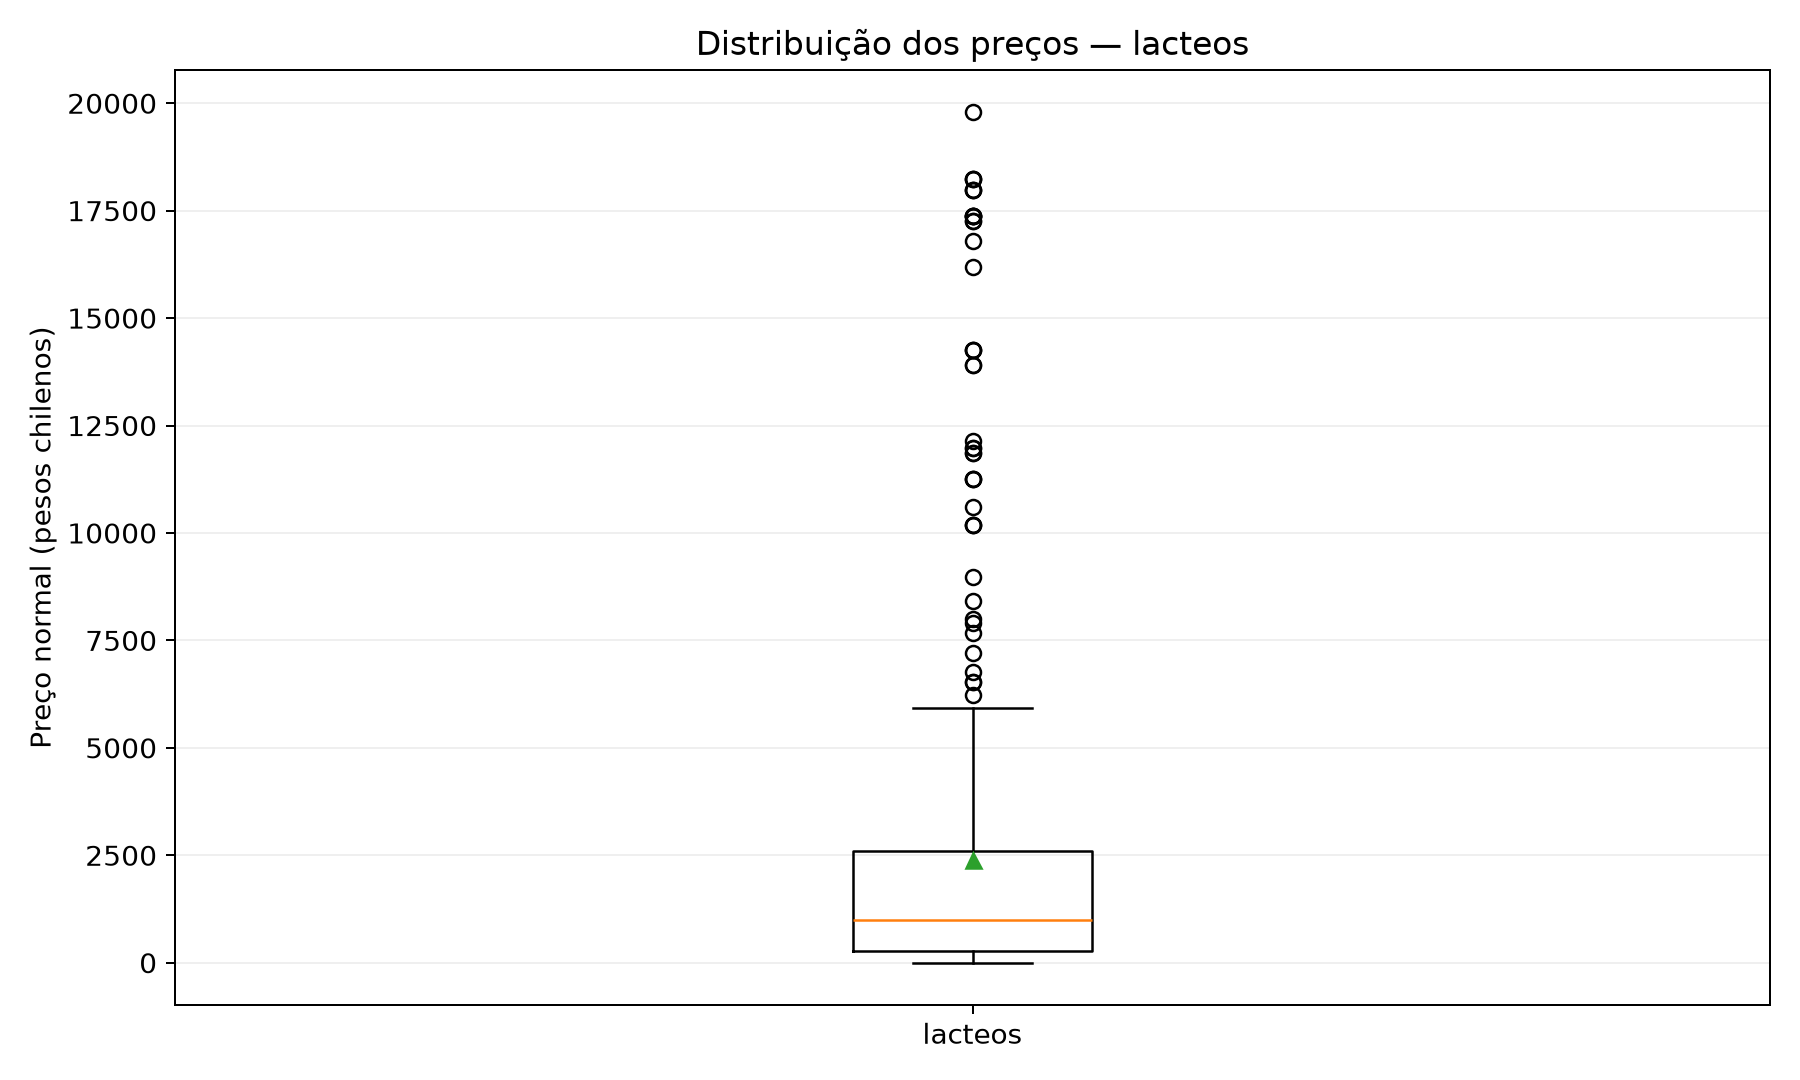

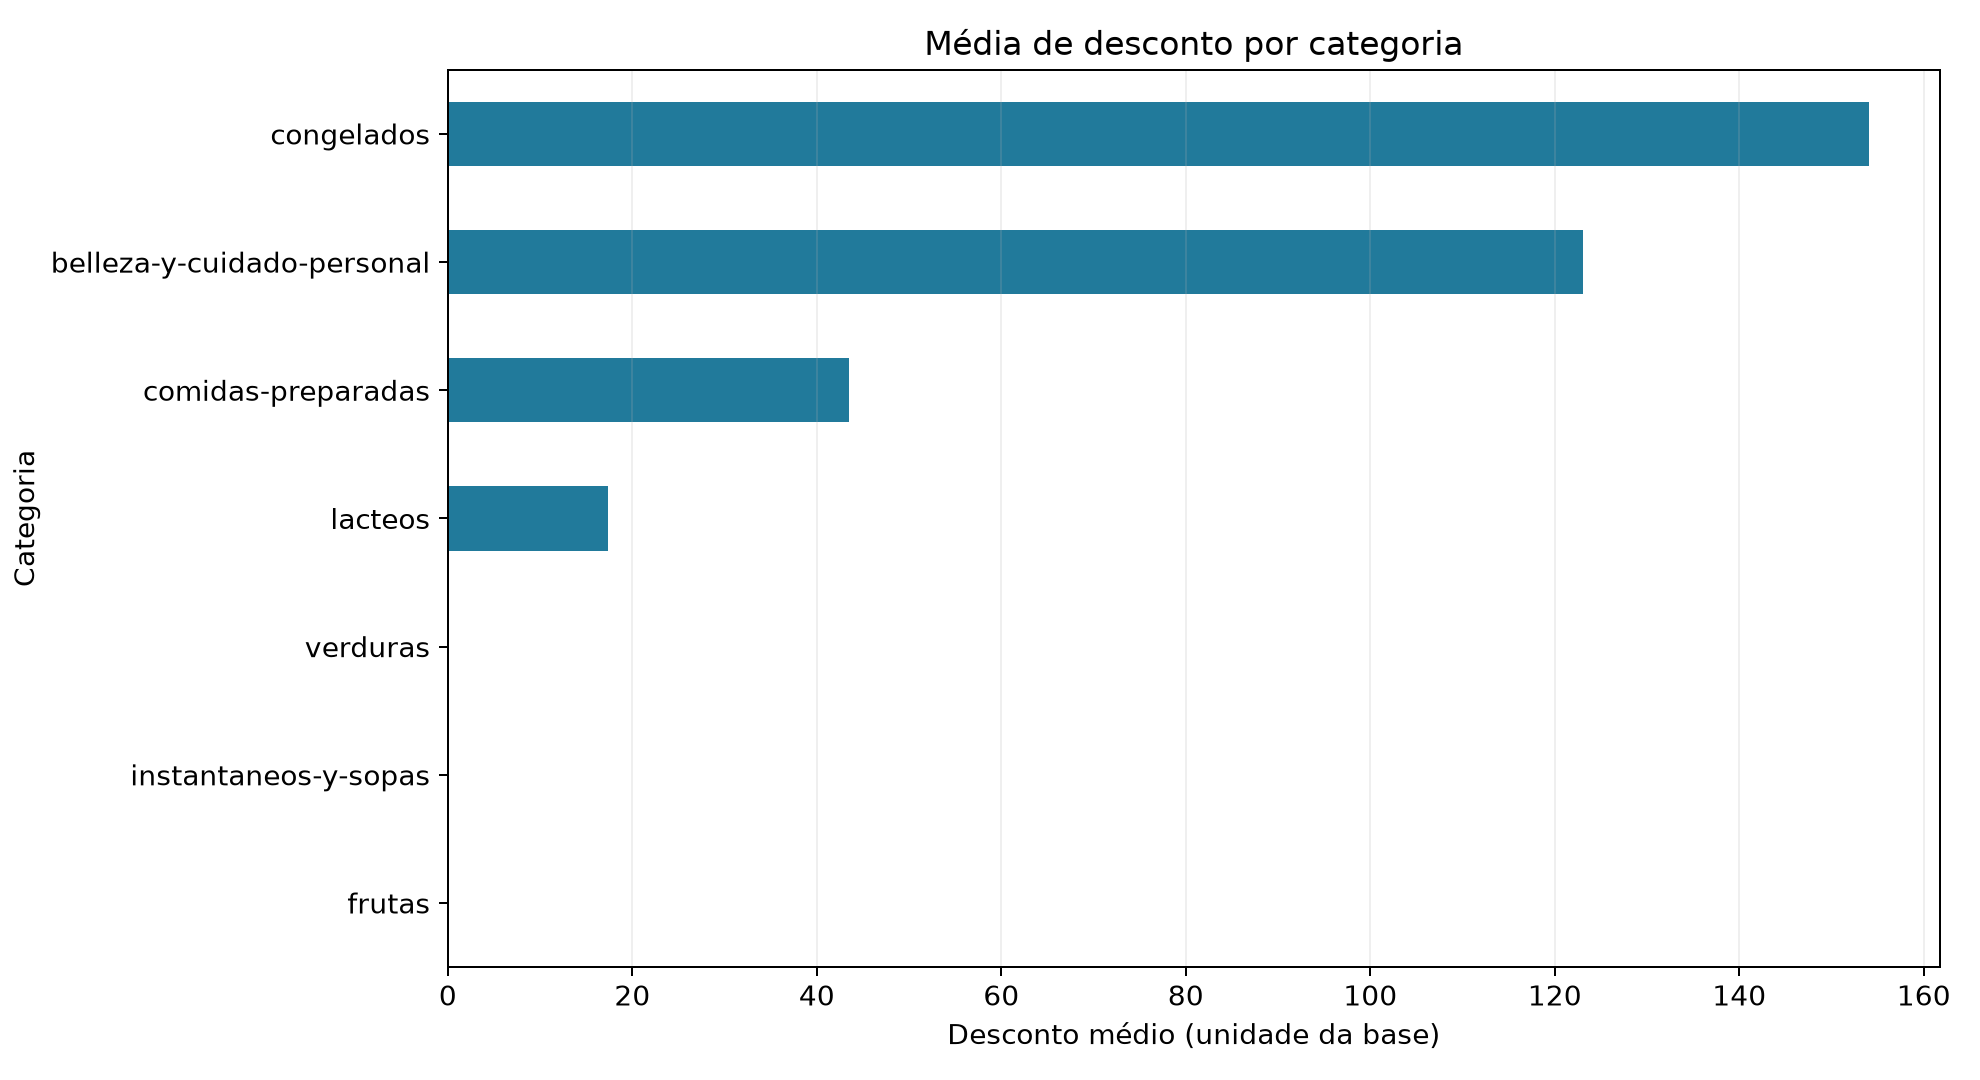

In [8]:
from IPython.display import display, Markdown, Image, IFrame
display(Markdown((SAIDA / "interpretacao.md").read_text(encoding="utf-8")))
display(Image(filename=str(SAIDA / "boxplot.png")))
display(Image(filename=str(SAIDA / "barras.png")))
display(IFrame(str(SAIDA / "mapa_interativo.html"), width="100%", height=850))